# 07 - Fuentes de la entrega final

En este notebook pasamos a la capa plata las fuentes de la entrega final. Van en rutas propias (`/nyc/*/entrega_final`) para no tocar las de la primera entrega.

| Fuente | De dónde sale | Para qué |
|---|---|---|
| Choques, vehículos y personas | NYC Open Data | Eventos, causas y gravedad por persona (KSI) |
| Población 2020 por sector censal | Censo de EE. UU., archivo geográfico de PL 94-171 | Denominador por barrio |
| Clima por hora | Open-Meteo (histórico 2019-2026) y OpenWeather (pronóstico de 5 días; su histórico es de pago) | Lluvia, nieve y temperatura de cada noche |
| Calendario | Construido en `noche.py` | Festivos y noches de eventos |

Volvimos a descargar choques y vehículos porque el 28 de octubre de 2026 NYC republicó las tres tablas de choques con identificadores nuevos, que ahora son textos de 32 caracteres. Los de personas no cruzan con los choques que bajamos en septiembre, así que bajamos las tres juntas. Los totales cambian un poco frente a la primera entrega y la diferencia queda en `tabla_07_comparacion_primera_entrega.csv`. Los arrestos, la pobreza y las fronteras no cambiaron, por eso los reutilizamos.

Antes de correrlo hay que descargar los datos con `scripts/ejecutar_entrega_final.sh descargar`.

Los faltantes no se llenan con moda, media ni mediana. Cuando se puede, el dato se recupera de otra columna, y cuando no, queda como categoría aparte o se excluye y se mide el efecto. Lo único que se puede interpolar es la temperatura, en huecos de hasta 2 horas y con una marca.

In [1]:
import json
import time

import numpy as np
import pandas as pd
import shapely.affinity
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

import geo
import noche
from codigos import DIAS_SEMANA
from config import BRONZE_FINAL, FECHA_FIN_CHOQUES, FECHA_INICIO, RAW_FINAL, SILVER, SILVER_FINAL, sesion
from decisiones import FRANJAS_NOCHE, KSI_VARIANTE
from estilo import BOROUGHS, CATEGORICA, TINTA_SECUNDARIA, dec, guardar

spark = sesion("07_fuentes_nuevas")
jvm = spark._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark.sparkContext._jsc.hadoopConfiguration())
Ruta = jvm.org.apache.hadoop.fs.Path

registro = []          # filas antes y después de cada paso (va al numeral 9 del documento)

def paso(tabla, descripcion, df_o_n):
    n = df_o_n if isinstance(df_o_n, (int, np.integer)) else df_o_n.count()
    registro.append({"tabla": tabla, "paso": descripcion, "registros": int(n)})
    print(f"{tabla:>14} | {descripcion:<62} {n:>12,}")

def listar(ruta):
    return [str(s.getPath()) for s in fs.listStatus(Ruta(ruta))] if fs.exists(Ruta(ruta)) else []

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/22 14:49:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Choques, vehículos y personas

Los CSV se leen como texto, se guardan en bronce y luego se les pone tipo en plata, menos a los identificadores, que se quedan como texto. La limpieza de choques y vehículos es la misma de `05_limpieza_inicial`.

In [2]:
def a_bronce(fuente):
    t0 = time.time()
    noche.leer_csv_crudo(spark, f"{RAW_FINAL}/{fuente}/").repartition(16).write.mode("overwrite").parquet(f"{BRONZE_FINAL}/{fuente}")
    df = spark.read.parquet(f"{BRONZE_FINAL}/{fuente}")
    print(f"{fuente}: bronce escrito en {time.time() - t0:.0f} s")
    paso(fuente, "1. registros descargados (solo el periodo)", df)
    return df.withColumn("fecha", noche.col_fecha(F.col("crash_date")))

ch = a_bronce("choques")
ve = a_bronce("vehiculos")
pe = a_bronce("personas")

26/11/22 14:49:49 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


choques: bronce escrito en 19 s


       choques | 1. registros descargados (solo el periodo)                          846,508


vehiculos: bronce escrito en 8 s


     vehiculos | 1. registros descargados (solo el periodo)                        1,711,019


personas: bronce escrito en 9 s


      personas | 1. registros descargados (solo el periodo)                        3,080,985


In [3]:
pumas = geo.cargar_pumas(spark)
dias = F.create_map(*[F.lit(x) for kv in DIAS_SEMANA.items() for x in kv])
ch = ch.filter(F.col("fecha").between(FECHA_INICIO, FECHA_FIN_CHOQUES)).dropDuplicates(["collision_id"])
lat, lon = F.col("latitude").try_cast("double"), F.col("longitude").try_cast("double")
valida = geo.coordenada_valida(lat, lon)
ch = (ch
    .withColumn("hora", F.split(F.col("crash_time"), ":").getItem(0).try_cast("int"))
    .withColumn("anio", F.year("fecha"))
    .withColumn("mes", F.month("fecha"))
    .withColumn("dia_semana", dias[F.dayofweek("fecha")])
    .withColumn("lat", F.when(valida, lat))
    .withColumn("lon", F.when(valida, lon))
    .withColumn("borough_original", F.when(F.trim("borough") != "", F.initcap(F.trim("borough"))))
    .withColumn("heridos", F.col("number_of_persons_injured").try_cast("int"))
    .withColumn("muertos", F.col("number_of_persons_killed").try_cast("int"))
    .withColumn("number_of_pedestrians_injured", F.col("number_of_pedestrians_injured").try_cast("int"))
    .withColumn("number_of_pedestrians_killed", F.col("number_of_pedestrians_killed").try_cast("int"))
    .withColumn("grave", (F.coalesce("heridos", F.lit(0)) + F.coalesce("muertos", F.lit(0))) > 0))
ch = geo.agregar_puma(ch, pumas, "lat", "lon", "puma")
ch.select(
    "collision_id", "fecha", "anio", "mes", "dia_semana", "hora",
    F.coalesce("borough_original", geo.borough_desde_puma(F.col("puma"))).alias("borough"), "borough_original",
    "puma", "lat", "lon", "heridos", "muertos", "grave",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    *[F.col(f"contributing_factor_vehicle_{i}").alias(f"factor_{i}") for i in range(1, 6)],
).write.mode("overwrite").partitionBy("anio").parquet(f"{SILVER_FINAL}/choques")
choques = spark.read.parquet(f"{SILVER_FINAL}/choques")
paso("choques", "2. escrito en plata (periodo, sin duplicados)", choques)
corte = choques.agg(F.max("fecha")).first()[0]
assert str(corte) == FECHA_FIN_CHOQUES, f"Los choques llegan hasta {corte} y deberían llegar hasta {FECHA_FIN_CHOQUES}"

       choques | 2. escrito en plata (periodo, sin duplicados)                       846,508


In [4]:
ve = ve.filter(F.col("fecha").between(FECHA_INICIO, str(corte))).dropDuplicates(["unique_id"])
ve.select("unique_id", "collision_id", "fecha", F.year("fecha").alias("anio"), F.col("vehicle_type").alias("tipo_vehiculo"),
          F.col("contributing_factor_1").alias("factor_1"), F.col("contributing_factor_2").alias("factor_2"),
).write.mode("overwrite").partitionBy("anio").parquet(f"{SILVER_FINAL}/vehiculos")
vehiculos = spark.read.parquet(f"{SILVER_FINAL}/vehiculos")
paso("vehiculos", "2. escrito en plata (periodo, sin duplicados)", vehiculos)

pe = pe.filter(F.col("fecha").between(FECHA_INICIO, str(corte)))
paso("personas", f"2. dentro del periodo {FECHA_INICIO} a {corte}", pe)
pe = pe.dropDuplicates(["unique_id"]).cache()
paso("personas", "3. sin UNIQUE_ID duplicados", pe)

     vehiculos | 2. escrito en plata (periodo, sin duplicados)                     1,711,019


      personas | 2. dentro del periodo 2019-01-01 a 2026-05-31                     3,080,985


      personas | 3. sin UNIQUE_ID duplicados                                       3,080,985


Revisamos las llaves antes de seguir. Si las tablas no cruzaran, los muertos y lesionados serios saldrían en cero sin ningún aviso, por eso el notebook se detiene en ese caso.

In [5]:
def cobertura(hija, col_hija, madre, col_madre):
    h = hija.filter(F.col(col_hija).isNotNull()).select(F.col(col_hija).alias("llave"))
    m = madre.select(F.col(col_madre).alias("llave")).distinct()
    return h.join(m, "llave", "left_semi").count() / max(h.count(), 1)

llaves = pd.DataFrame([
    {"cruce": "personas con su choque", "cobertura": cobertura(pe, "collision_id", choques, "collision_id"), "minimo": 0.99},
    {"cruce": "vehículos con su choque", "cobertura": cobertura(vehiculos, "collision_id", choques, "collision_id"), "minimo": 0.99},
    {"cruce": "personas con su vehículo", "cobertura": cobertura(pe, "vehicle_id", vehiculos, "unique_id"), "minimo": 0.95}])
llaves.to_csv("../figuras/tabla_07_cobertura_llaves.csv", index=False)
print(llaves.to_string(index=False))
assert (llaves["cobertura"] >= llaves["minimo"]).all(), "Las tablas no cruzan: revisar los identificadores antes de seguir"

                   cruce  cobertura  minimo
  personas con su choque        1.0    0.99
 vehículos con su choque        1.0    0.99
personas con su vehículo        1.0    0.95


Comparamos con los datos de la primera entrega, descargados el 27 de septiembre.

In [6]:
comparacion = []
for nombre, nueva in (("choques", choques), ("vehiculos", vehiculos)):
    d = (spark.read.parquet(f"{SILVER}/{nombre}").groupBy("anio").agg(F.count("*").alias("primera_entrega"))
         .join(nueva.groupBy("anio").agg(F.count("*").alias("entrega_final")), "anio", "outer").orderBy("anio").toPandas())
    d.insert(0, "tabla", nombre)
    comparacion.append(d)
comparacion = pd.concat(comparacion, ignore_index=True)
comparacion["diferencia"] = comparacion["entrega_final"] - comparacion["primera_entrega"]
comparacion.to_csv("../figuras/tabla_07_comparacion_primera_entrega.csv", index=False)
comparacion

,tabla,anio,primera_entrega,entrega_final,diferencia
0,choques,2019,211486,211487,1
1,choques,2020,112918,112924,6
2,choques,2021,110558,110558,0
3,choques,2022,103887,103888,1
4,choques,2023,96607,96608,1
5,choques,2024,91316,91317,1
6,choques,2025,85546,85559,13
7,choques,2026,34102,34167,65
8,vehiculos,2019,426724,426726,2
9,vehiculos,2020,231211,231224,13


Miramos los valores reales de los campos de lesión para confirmar que las expresiones regulares de `decisiones.py` encuentran lo que deben antes de usar la definición de KSI.

In [7]:
for columna in ["person_type", "person_injury", "emotional_status", "complaint"]:
    tabla = (pe.groupBy(F.upper(F.trim(columna)).alias(columna)).count()
               .orderBy(F.desc("count")).toPandas())
    tabla["%"] = (100 * tabla["count"] / tabla["count"].sum()).round(2)
    tabla.to_csv(f"../figuras/tabla_07_valores_{columna}.csv", index=False)
    print(f"\n=== {columna} ({len(tabla)} valores distintos) ===")
    print(tabla.head(30).to_string(index=False))


=== person_type (4 valores distintos) ===
    person_type   count     %
       OCCUPANT 2947376 95.66
     PEDESTRIAN   71361  2.32
      BICYCLIST   46304  1.50
OTHER MOTORIZED   15944  0.52



=== person_injury (3 valores distintos) ===
person_injury   count     %
  UNSPECIFIED 2692226 87.38
      INJURED  386791 12.55
       KILLED    1968  0.06



=== emotional_status (9 valores distintos) ===
emotional_status   count     %
            None 1393918 45.24
  DOES NOT APPLY 1295182 42.04
       CONSCIOUS  355798 11.55
           SHOCK   14991  0.49
         UNKNOWN   13600  0.44
     UNCONSCIOUS    2275  0.07
   SEMICONSCIOUS    2156  0.07
  APPARENT DEATH    1679  0.05
      INCOHERENT    1386  0.04



=== complaint (22 valores distintos) ===
                         complaint   count     %
                              None 1393914 45.24
                    DOES NOT APPLY 1298318 42.14
       COMPLAINT OF PAIN OR NAUSEA  231043  7.50
                      NONE VISIBLE   43008  1.40
                    MINOR BLEEDING   22450  0.73
                CONTUSION - BRUISE   20304  0.66
                          WHIPLASH   18311  0.59
                           UNKNOWN   16855  0.55
                          ABRASION   13096  0.43
FRACTURE - DISTORTED - DISLOCATION    6817  0.22
                          INTERNAL    6528  0.21
                        CONCUSSION    2918  0.09
                    CRUSH INJURIES    2035  0.07
                   SEVERE BLEEDING    1903  0.06
                SEVERE LACERATIONS    1545  0.05
                        MINOR BURN    1097  0.04
                 COMPLAINT OF PAIN     445  0.01
                     MODERATE BURN     164  0.01
                        AMP

In [8]:
hora = F.split(F.col("crash_time"), ":")
personas = (pe
    .withColumn("hora", hora.getItem(0).try_cast("int"))
    .withColumn("anio", F.year("fecha"))
    .withColumn("tipo_persona", F.initcap(F.trim("person_type")))
    .withColumn("lesion_reportada", F.initcap(F.trim("person_injury")))
    .withColumn("muerto", F.coalesce(F.upper(F.trim("person_injury")) == "KILLED", F.lit(False)))
    .withColumn("lesionado", F.coalesce(F.upper(F.trim("person_injury")).isin("INJURED", "KILLED"), F.lit(False)))
    .withColumn("ksi_estricta", noche.col_ksi_persona(F.col("person_injury"), F.col("emotional_status"), F.col("complaint"), "estricta"))
    .withColumn("ksi_amplia", noche.col_ksi_persona(F.col("person_injury"), F.col("emotional_status"), F.col("complaint"), "amplia"))
    .withColumn("ksi", F.col(f"ksi_{KSI_VARIANTE}"))
    # Lesionado sin detalle: dice "Injured" pero la queja es desconocida o no aplica.
    # No se imputa; sirve para dar la cota superior de KSI (notebook 08).
    .withColumn("lesion_sin_detalle", F.col("lesionado") & ~F.col("muerto") &
                (F.col("complaint").isNull() | F.upper(F.trim("complaint")).isin("UNKNOWN", "DOES NOT APPLY", "")))
    .withColumn("edad", F.when(F.col("person_age").try_cast("int").between(0, 110), F.col("person_age").try_cast("int")))
    .select("unique_id", "collision_id", "fecha", "anio", "hora", "tipo_persona", "lesion_reportada",
            "muerto", "lesionado", "ksi", "ksi_estricta", "ksi_amplia", "lesion_sin_detalle",
            F.col("vehicle_id").alias("vehicle_id"), "edad", F.col("person_sex").alias("sexo"),
            F.col("emotional_status").alias("estado_emocional"), F.col("complaint").alias("queja"),
            F.col("bodily_injury").alias("parte_cuerpo"), F.col("safety_equipment").alias("equipo_seguridad"),
            F.col("position_in_vehicle").alias("posicion"), F.col("ped_location").alias("ubicacion_peaton"),
            F.col("ped_action").alias("accion_peaton"), F.col("ejection").alias("eyeccion"),
            F.col("contributing_factor_1").alias("factor_persona_1"),
            F.col("contributing_factor_2").alias("factor_persona_2"))
)
# ¿Cada persona tiene su choque en la plata?
ids = choques.select("collision_id").withColumn("tiene_choque", F.lit(True))
personas = personas.join(ids, "collision_id", "left").withColumn("tiene_choque", F.coalesce("tiene_choque", F.lit(False)))
personas.write.mode("overwrite").partitionBy("anio").parquet(f"{SILVER_FINAL}/personas")
personas = spark.read.parquet(f"{SILVER_FINAL}/personas")
paso("personas", "4. escrito en plata", personas)

personas.groupBy("tiene_choque").agg(
    F.count("*").alias("personas"), F.sum(F.col("muerto").cast("int")).alias("muertos"),
    F.sum(F.col("ksi_estricta").cast("int")).alias("ksi_estricta"),
    F.sum(F.col("ksi_amplia").cast("int")).alias("ksi_amplia"),
    F.sum(F.col("lesion_sin_detalle").cast("int")).alias("lesionados_sin_detalle")).toPandas()

      personas | 4. escrito en plata                                               3,080,985


,tiene_choque,personas,muertos,ksi_estricta,ksi_amplia,lesionados_sin_detalle
0,True,3080985,1968,22004,24738,16776


Los muertos de la tabla de personas deberían coincidir con `number_of_persons_killed` de la tabla de choques, así que los comparamos año por año.

In [9]:
muertos_personas = personas.filter("tiene_choque").groupBy("anio").agg(F.sum(F.col("muerto").cast("int")).alias("muertos_tabla_personas"))
muertos_choques = choques.groupBy("anio").agg(F.sum("muertos").alias("muertos_tabla_choques"))
consistencia = muertos_choques.join(muertos_personas, "anio", "outer").orderBy("anio").toPandas()
consistencia["diferencia"] = consistencia["muertos_tabla_personas"] - consistencia["muertos_tabla_choques"]
consistencia.to_csv("../figuras/tabla_07_consistencia_muertos.csv", index=False)
consistencia

,anio,muertos_tabla_choques,muertos_tabla_personas,diferencia
0,2019,244,244,0
1,2020,269,269,0
2,2021,297,297,0
3,2022,290,290,0
4,2023,280,280,0
5,2024,268,268,0
6,2025,229,229,0
7,2026,91,91,0


## 2. Población 2020 por barrio

El censo publica la población de los 2.327 sectores censales de la ciudad con un punto interior para cada uno. Con ese punto ubicamos cada sector en su PUMA, usando el cruce espacial de la primera entrega, y sumamos. Es una aproximación, porque los sectores de 2020 no siguen exactamente las fronteras de las PUMA de 2010. En algunos sectores de la orilla el punto cae justo por fuera de las fronteras, que siguen la costa. A esos los llevamos a la PUMA más cercana del mismo distrito, hasta 500 metros, y los dejamos anotados en `tabla_07_sectores_reasignados.csv`. Al final los barrios de cada distrito tienen que sumar lo que publicó el censo.

In [10]:
censo = spark.read.option("header", True).csv(f"{RAW_FINAL}/censo2020/").toPandas()
censo["poblacion_2020"] = censo["poblacion_2020"].astype("int64")
for c in ("lat", "lon"):
    censo[c] = censo[c].astype(float)
censo["area_tierra_km2"] = censo["area_tierra_m2"].astype(float) / 1e6
print(f"{len(censo):,} sectores censales, {censo['poblacion_2020'].sum():,} habitantes")
censo_sp = spark.createDataFrame(censo[["geoid", "county", "poblacion_2020", "lat", "lon", "area_tierra_km2"]])
censo_sp = geo.agregar_puma(censo_sp, pumas, "lat", "lon", "puma").toPandas()

CONDADO = {"005": "Bronx", "047": "Brooklyn", "061": "Manhattan", "081": "Queens", "085": "Staten Island"}
censo_sp["borough"] = censo_sp["county"].map(CONDADO)
sin_puma = censo_sp[censo_sp["puma"].isna()]
print(f"Sectores sin PUMA: {len(sin_puma)} ({sin_puma['poblacion_2020'].sum():,} habitantes, "
      f"{100 * sin_puma['poblacion_2020'].sum() / censo_sp['poblacion_2020'].sum():.2f} % de la ciudad)")

2,327 sectores censales, 8,804,190 habitantes


Sectores sin PUMA: 10 (36,148 habitantes, 0.41 % de la ciudad)


Los sectores con habitantes que quedaron por fuera van a la PUMA más cercana de su distrito. Los que son solo agua no tienen habitantes y se dejan sin asignar.

In [11]:
MAX_METROS_ORILLA = 500

def metros_a_puma(lat, lon, wkb):
    # a esta escala basta corregir la longitud por el coseno de la latitud
    k = np.cos(np.radians(lat))
    poligono = shapely.affinity.scale(shapely.from_wkb(wkb), xfact=k, origin=(0, 0))
    return poligono.distance(shapely.Point(lon * k, lat)) * 110_950

reasignados = []
for i, s in sin_puma[sin_puma["poblacion_2020"] > 0].iterrows():
    candidatas = pumas[pumas["borough"] == s["borough"]]
    metros, puma = min((metros_a_puma(s["lat"], s["lon"], w), p) for p, w in zip(candidatas["puma"], candidatas["wkb"]))
    assert metros <= MAX_METROS_ORILLA, f"El sector {s['geoid']} está a {metros:.0f} m de su PUMA más cercana"
    censo_sp.loc[i, "puma"] = puma
    reasignados.append({"geoid": s["geoid"], "borough": s["borough"], "poblacion_2020": int(s["poblacion_2020"]),
                        "puma": puma, "metros": round(float(metros), 1)})
reasignados = pd.DataFrame(reasignados, columns=["geoid", "borough", "poblacion_2020", "puma", "metros"])
reasignados.to_csv("../figuras/tabla_07_sectores_reasignados.csv", index=False)
print(f"Sectores llevados a la PUMA más cercana: {len(reasignados)} ({reasignados['poblacion_2020'].sum():,} habitantes)")
print(reasignados.to_string(index=False))

Sectores llevados a la PUMA más cercana: 7 (36,148 habitantes)
      geoid   borough  poblacion_2020 puma  metros
36047102802  Brooklyn               5 4009    45.0
36061000202 Manhattan            7266 3809    12.5
36061006200 Manhattan            3686 3808   156.4
36061012901 Manhattan            7959 3807     1.0
36061012902 Manhattan            3144 3807     4.0
36061013502 Manhattan            6358 3807     9.9
36061015200 Manhattan            7730 3805    51.5


Comparamos con los totales oficiales del censo 2020 por condado. Si un distrito no cuadra, el notebook se detiene.

In [12]:
OFICIAL_2020 = {"Bronx": 1_472_654, "Brooklyn": 2_736_074, "Manhattan": 1_694_251,
                "Queens": 2_405_464, "Staten Island": 495_747}
por_borough = censo_sp.groupby("borough")["poblacion_2020"].sum().reindex(BOROUGHS)
validacion = pd.DataFrame({"censo_suma_sectores": por_borough, "censo_oficial": pd.Series(OFICIAL_2020)})
validacion["coincide"] = validacion["censo_suma_sectores"] == validacion["censo_oficial"]
print(validacion)
assert validacion["coincide"].all(), "La suma de los sectores no da el total oficial del condado"

# Borough de la PUMA frente al condado del sector: los que no coinciden son puntos mal ubicados
asignados = censo_sp[censo_sp["puma"].notna()].copy()
asignados["borough_puma"] = asignados["puma"].str[:2].map(geo.BOROUGH_POR_PREFIJO)
cruzados = asignados[asignados["borough_puma"] != asignados["borough"]]
print(f"Sectores cuya PUMA es de otro distrito: {len(cruzados)} ({cruzados['poblacion_2020'].sum():,} hab.)")

               censo_suma_sectores  censo_oficial  coincide
Bronx                      1472654        1472654      True
Brooklyn                   2736074        2736074      True
Manhattan                  1694251        1694251      True
Queens                     2405464        2405464      True
Staten Island               495747         495747      True
Sectores cuya PUMA es de otro distrito: 0 (0 hab.)


In [13]:
poblacion_puma = (asignados.groupby("puma")
                  .agg(poblacion_2020=("poblacion_2020", "sum"), area_tierra_km2=("area_tierra_km2", "sum"),
                       sectores=("geoid", "count")).reset_index())
poblacion_puma["borough"] = poblacion_puma["puma"].str[:2].map(geo.BOROUGH_POR_PREFIJO)
poblacion_puma["densidad_km2"] = poblacion_puma["poblacion_2020"] / poblacion_puma["area_tierra_km2"]
assert len(poblacion_puma) == 55, f"Hay {len(poblacion_puma)} PUMAs con población"
suma_barrios = poblacion_puma.groupby("borough")["poblacion_2020"].sum().to_dict()
assert suma_barrios == OFICIAL_2020, f"Los barrios no suman el total oficial de su distrito: {suma_barrios}"

print(poblacion_puma["poblacion_2020"].describe().round(0))
spark.createDataFrame(poblacion_puma).write.mode("overwrite").parquet(f"{SILVER_FINAL}/poblacion_puma_2020")
poblacion_puma.to_csv("../figuras/tabla_07_poblacion_puma_2020.csv", index=False)
paso("poblacion", "PUMAs con población 2020", len(poblacion_puma))

count        55.0
mean     160076.0
std       34276.0
min      110492.0
25%      134088.0
50%      155282.0
75%      178649.0
max      270930.0
Name: poblacion_2020, dtype: float64


     poblacion | PUMAs con población 2020                                                 55


## 3. Clima por hora

### 3.1 OpenWeather
Leemos el registro que dejó `extraer_clima.py` con la respuesta de cada producto de la API. Lo que la clave haya dejado descargar se carga y se compara con Open-Meteo.

Consultado: 2026-11-22T17:19:07+00:00
            producto   http                                                                           mensaje
              actual  200.0                                                                               NaN
   pronostico_5_dias    200                                                                                 0
  historico_por_hora    401 Invalid API key. Please see http://openweathermap.org/faq#error401 for more info.
estadisticas_anuales    401 Invalid API key. Please see http://openweathermap.org/faq#error401 for more info.
Horas de histórico de OpenWeather: 0


Pronóstico guardado: 40 pasos de 3 horas desde 2026-11-22 13:00:00


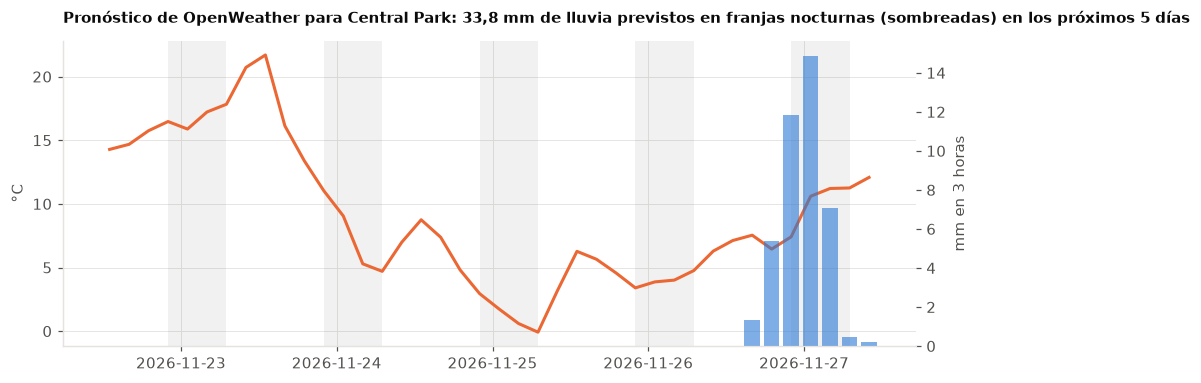

In [14]:
estado_ow = None
ruta_estado = f"{RAW_FINAL}/clima/openweather/openweather_estado.json"
if fs.exists(Ruta(ruta_estado)):
    estado_ow = json.loads(spark.read.text(ruta_estado, wholetext=True).first()[0])
    tabla_ow = pd.DataFrame(estado_ow["productos"]).T.reset_index().rename(columns={"index": "producto"})
    tabla_ow.to_csv("../figuras/tabla_07_openweather_estado.csv", index=False)
    print("Consultado:", estado_ow["consultado_utc"])
    print(tabla_ow.to_string(index=False))
else:
    print("No hay registro de OpenWeather (no se corrió con clave).")

def leer_jsons(carpeta):
    return [json.loads(t) for _, t in spark.sparkContext.wholeTextFiles(carpeta).collect()] \
        if fs.exists(Ruta(carpeta)) else []

# Histórico por hora de OpenWeather (si la clave lo permitió)
ow_hist = []
for doc in leer_jsons(f"{RAW_FINAL}/clima/openweather/historico"):
    for r in doc.get("list", []):
        ow_hist.append({"ts_utc": pd.to_datetime(r["dt"], unit="s", utc=True),
                        "temp_ow": r.get("main", {}).get("temp"),
                        "lluvia_1h_ow": (r.get("rain") or {}).get("1h", 0.0),
                        "nieve_1h_ow": (r.get("snow") or {}).get("1h", 0.0)})
ow_hist = pd.DataFrame(ow_hist)
print(f"Horas de histórico de OpenWeather: {len(ow_hist):,}")

# Pronóstico de 5 días (sirve para la demostración operativa del notebook 11)
pronosticos = leer_jsons(f"{RAW_FINAL}/clima/openweather/pronostico_5_dias")
if pronosticos:
    ultimo = max(pronosticos, key=lambda d: d["list"][0]["dt"])
    pron = pd.DataFrame([{"ts_utc": pd.to_datetime(r["dt"], unit="s", utc=True),
                          "temp": r["main"]["temp"], "lluvia_3h": (r.get("rain") or {}).get("3h", 0.0),
                          "nieve_3h": (r.get("snow") or {}).get("3h", 0.0),
                          "viento_kmh": 3.6 * (r.get("wind") or {}).get("speed", float("nan")), "descripcion": r["weather"][0]["description"]}
                         for r in ultimo["list"]])
    pron["ts_local"] = pron["ts_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
    # la hora local se guarda como texto para que la zona horaria de Spark no la mueva
    spark.createDataFrame(pron.drop(columns=["ts_utc"]).assign(ts_local=pron["ts_local"].dt.strftime("%Y-%m-%d %H:%M"))).write.mode("overwrite").parquet(f"{SILVER_FINAL}/clima_pronostico")
    print(f"Pronóstico guardado: {len(pron)} pasos de 3 horas desde {pron['ts_local'].min()}")
    pron.drop(columns=["ts_utc"]).to_csv("../figuras/tabla_07_pronostico_openweather.csv", index=False)

    # Gráfica del pronóstico que se bajó de OpenWeather
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(pron["ts_local"], pron["temp"], color=CATEGORICA[1], label="temperatura (°C)")
    ax2 = ax.twinx()
    ax2.bar(pron["ts_local"], pron["lluvia_3h"], width=0.1, color=CATEGORICA[0], alpha=0.6, label="lluvia en 3 h (mm)")
    ax2.set_ylabel("mm en 3 horas"); ax2.grid(False)
    ax.set_ylabel("°C")
    # cada paso cubre 3 horas; es nocturno si empieza en una franja de la noche (21-23, 00-02, 03-05)
    noches = pron[(pron["ts_local"].dt.hour // 3).isin(FRANJAS_NOCHE)]
    for t in noches["ts_local"]:
        ax.axvspan(t, t + pd.Timedelta(hours=3), color=TINTA_SECUNDARIA, alpha=0.08, linewidth=0)
    lluvia_noche = noches["lluvia_3h"].sum()
    ax.set_title(f"Pronóstico de OpenWeather para Central Park: {dec(lluvia_noche)} mm de lluvia previstos en franjas nocturnas "
                 f"(sombreadas) en los próximos 5 días", fontsize=10, pad=12)
    guardar(fig, "07_01_pronostico_openweather")
    plt.show()

### 3.2 Open-Meteo

In [15]:
om = []
for doc in leer_jsons(f"{RAW_FINAL}/clima/open_meteo"):
    om.append(pd.DataFrame(doc["hourly"]))
om = pd.concat(om, ignore_index=True)
om, faltan = noche.horas_locales(om, FECHA_INICIO, FECHA_FIN_CHOQUES)
print(f"{len(om):,} horas locales de {om['ts_local'].min()} a {om['ts_local'].max()} | sin dato en la fuente: {faltan}")
assert faltan < 0.01 * len(om), "Falta más del 1 % de las horas de clima: repetir la descarga"
print("Valores vacíos por variable:\n", om.isna().sum()[om.isna().sum() > 0])

64,984 horas locales de 2019-01-01 00:00:00 a 2026-05-31 23:00:00 | sin dato en la fuente: 0
Valores vacíos por variable:
 Series([], dtype: int64)


Pedimos el clima en UTC y lo pasamos a la hora de Nueva York, que es la de los choques, porque si se pide en hora local la API no aplica el horario de verano. La temperatura se interpola en línea recta en huecos de hasta 2 horas y queda marcada en `temp_imputada`. La lluvia y la nieve no se interpolan, ya que una hora sin dato puede haber sido lluviosa.

In [16]:
temp_original = om["temperature_2m"].copy()
om["temperature_2m"] = om["temperature_2m"].astype(float).interpolate(limit=2, limit_area="inside")
om["temp_imputada"] = temp_original.isna() & om["temperature_2m"].notna()
print("Horas con temperatura imputada:", int(om["temp_imputada"].sum()))

clima = pd.DataFrame({
    "fecha": om["ts_local"].dt.strftime("%Y-%m-%d"),
    "hora": om["ts_local"].dt.hour,
    "temperatura": om["temperature_2m"],
    "temp_imputada": om["temp_imputada"],
    "sensacion": om["apparent_temperature"],
    "humedad": om["relative_humidity_2m"],
    "precipitacion_mm": om["precipitation"],
    "lluvia_mm": om["rain"],
    "nieve_cm": om["snowfall"],
    "nieve_suelo_m": om["snow_depth"],
    "codigo_tiempo": om["weather_code"],
    "nubosidad": om["cloud_cover"],
    "viento_kmh": om["wind_speed_10m"],
    "rafagas_kmh": om["wind_gusts_10m"],
})
MEDIDAS_CLIMA = ["temperatura", "sensacion", "humedad", "precipitacion_mm", "lluvia_mm", "nieve_cm",
                 "nieve_suelo_m", "codigo_tiempo", "nubosidad", "viento_kmh", "rafagas_kmh"]
clima[MEDIDAS_CLIMA] = clima[MEDIDAS_CLIMA].astype(float)
clima["fuente"] = "open-meteo"

clima_sp = spark.createDataFrame(clima)
for c in MEDIDAS_CLIMA:                        # un dato vacío es nulo, no NaN
    clima_sp = clima_sp.withColumn(c, F.when(~F.isnan(c), F.col(c)))
clima_sp = (clima_sp
            .withColumn("fecha", F.to_date("fecha"))
            # Si no hay dato de precipitación, "llueve" queda nulo, no falso
            .withColumn("llueve", F.when(~F.isnan("precipitacion_mm") & F.col("precipitacion_mm").isNotNull(),
                                         F.col("precipitacion_mm") >= 0.1))
            .withColumn("nieva", F.when(~F.isnan("nieve_cm") & F.col("nieve_cm").isNotNull(), F.col("nieve_cm") > 0))
            .withColumn("franja", noche.col_franja(F.col("hora")))
            .withColumn("fecha_noche", noche.col_fecha_noche(F.col("fecha"), F.col("hora"))))
clima_sp.write.mode("overwrite").parquet(f"{SILVER_FINAL}/clima_hora")
paso("clima", "horas en plata (Open-Meteo)", spark.read.parquet(f"{SILVER_FINAL}/clima_hora"))

Horas con temperatura imputada: 0


         clima | horas en plata (Open-Meteo)                                          64,984


Si OpenWeather dio histórico, aquí se compara con Open-Meteo en las horas que coinciden.

In [17]:
if len(ow_hist):
    ow_hist["ts_local"] = ow_hist["ts_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
    comp = ow_hist.merge(om[["ts_local", "temperature_2m", "precipitation"]], on="ts_local")
    r_temp = comp["temp_ow"].corr(comp["temperature_2m"])
    acuerdo_lluvia = ((comp["lluvia_1h_ow"] >= 0.1) == (comp["precipitation"] >= 0.1)).mean()
    print(f"Horas comparadas: {len(comp):,} | correlación de temperatura: {r_temp:.3f} | "
          f"acuerdo en hora lluviosa sí/no: {100 * acuerdo_lluvia:.1f} %")
else:
    print("Sin histórico de OpenWeather: el modelo usa Open-Meteo y OpenWeather queda para el pronóstico operativo.")

Sin histórico de OpenWeather: el modelo usa Open-Meteo y OpenWeather queda para el pronóstico operativo.


In [18]:
diario = clima.assign(anio=clima["fecha"].str[:4].astype(int), llueve=clima["precipitacion_mm"] >= 0.1).groupby("anio").agg(
    horas=("hora", "size"), horas_con_lluvia=("llueve", "sum"), nieve_cm=("nieve_cm", "sum"),
    temp_media=("temperatura", "mean")).round(1)
diario.to_csv("../figuras/tabla_07_clima_por_anio.csv")
diario

,horas,horas_con_lluvia,nieve_cm,temp_media
anio,,,,
2019,8759,1571,68.1,12.0
2020,8783,1465,32.4,12.8
2021,8759,1415,67.3,12.7
2022,8759,1269,51.2,12.4
2023,8759,1334,24.9,13.0
2024,8783,1309,45.9,13.0
2025,8759,1205,49.1,12.4
2026,3623,483,63.9,6.4


## 4. Calendario de festivos y noches de eventos

In [19]:
cal = pd.DataFrame(noche.calendario(2019, 2026))
cal["fecha"] = cal["fecha"].astype(str)
spark.createDataFrame(cal).withColumn("fecha", F.to_date("fecha")).write.mode("overwrite").parquet(f"{SILVER_FINAL}/calendario")
cal.to_csv("../figuras/tabla_07_calendario.csv", index=False)
print(cal.groupby("tipo").size())
paso("calendario", "fechas de festivos y eventos", len(cal))

tipo
evento     72
festivo    86
dtype: int64
    calendario | fechas de festivos y eventos                                            158


## 5. Registro de pasos

In [20]:
registro_df = pd.DataFrame(registro)
registro_df.to_csv("../figuras/tabla_07_registro.csv", index=False)
registro_df

,tabla,paso,registros
0,choques,1. registros descargados (solo el periodo),846508
1,vehiculos,1. registros descargados (solo el periodo),1711019
2,personas,1. registros descargados (solo el periodo),3080985
3,choques,"2. escrito en plata (periodo, sin duplicados)",846508
4,vehiculos,"2. escrito en plata (periodo, sin duplicados)",1711019
5,personas,2. dentro del periodo 2019-01-01 a 2026-05-31,3080985
6,personas,3. sin UNIQUE_ID duplicados,3080985
7,personas,4. escrito en plata,3080985
8,poblacion,PUMAs con población 2020,55
9,clima,horas en plata (Open-Meteo),64984


## Conclusiones

Las tres tablas cruzaron completas y los muertos coinciden todos los años, así que podemos medir la gravedad persona por persona. Los valores de los campos de lesión quedaron en `tabla_07_valores_*.csv`.

Siete sectores de la orilla, con 36.148 habitantes, pasaron al barrio más cercano y con eso la población por barrio suma el total oficial de cada distrito.

El histórico por hora de OpenWeather es de pago (respondió 401), por lo que el clima de 2019 a 2026 sale de Open-Meteo y de OpenWeather queda el pronóstico. El clima llegó completo y no hubo que interpolar ninguna hora.